In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, learning_curve, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import optuna

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

print("Optimization and modeling packages loaded successfully.")


Optimization and modeling packages loaded successfully.


In [2]:
df = pd.read_csv("womens_clothing_regression_dataset.csv")
print(f"Dataset shape: {df.shape}")

features = [
    'Length_of_Membership',
    'Time_on_App',
    'Avg_Session_Length',
    'Time_on_Website',
    'Annual_Orders',
    'Avg_Order_Value',
    'Age'
]
target = 'Yearly_Amount_Spent'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training observations: {len(X_train)}, Test observations: {len(X_test)}")


Dataset shape: (23465, 20)
Training observations: 18772, Test observations: 4693


In [3]:
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)

r2_tr_base = r2_score(y_train, rf_base.predict(X_train))
r2_te_base = r2_score(y_test, rf_base.predict(X_test))
rmse_te_base = np.sqrt(mean_squared_error(y_test, rf_base.predict(X_test)))

print(f"Baseline Train R²: {r2_tr_base:.4f}")
print(f"Baseline Test R² : {r2_te_base:.4f} (Train-Test Gap: {r2_tr_base - r2_te_base:.4f})")
print(f"Baseline Test RMSE: ${rmse_te_base:.2f}")


Baseline Train R²: 0.9932
Baseline Test R² : 0.9538 (Train-Test Gap: 0.0395)
Baseline Test RMSE: $31.57


In [4]:
df_grid_top = pd.read_csv("gridsearch_top_candidates.csv")
print("Top 5 GridSearchCV Parameter Configurations:")
df_grid_top


Top 5 GridSearchCV Parameter Configurations:


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,"{'max_depth': 16, 'min_samples_leaf': 2, 'min_...",0.950555,0.001781,10.104142,1
1,"{'max_depth': 16, 'min_samples_leaf': 2, 'min_...",0.949857,0.001728,4.926167,2
2,"{'max_depth': 16, 'min_samples_leaf': 2, 'min_...",0.949772,0.001803,8.996464,3
3,"{'max_depth': 12, 'min_samples_leaf': 2, 'min_...",0.949397,0.001920,8.567508,4
4,"{'max_depth': 16, 'min_samples_leaf': 2, 'min_...",0.949178,0.001764,4.954532,5


In [5]:
df_rand_top = pd.read_csv("randomsearch_top_candidates.csv")
print("Top 5 RandomizedSearchCV Parameter Configurations:")
df_rand_top


Top 5 RandomizedSearchCV Parameter Configurations:


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,"{'max_depth': 17, 'max_features': 'sqrt', 'min...",0.951772,0.001421,5.753352,1
1,"{'max_depth': 16, 'max_features': 'sqrt', 'min...",0.951186,0.001464,6.349690,2
2,"{'max_depth': 15, 'max_features': 'sqrt', 'min...",0.950975,0.001413,4.808712,3
3,"{'max_depth': 17, 'max_features': 1.0, 'min_sa...",0.950254,0.001731,6.132177,4
4,"{'max_depth': 13, 'max_features': 1.0, 'min_sa...",0.950130,0.001801,10.745761,5


In [6]:
df_optuna = pd.read_csv("bayesian_optuna_trials_summary.csv")
print(f"Total Optuna Trials Completed: {len(df_optuna)}")
df_optuna[['number', 'value', 'params_max_depth', 'params_n_estimators', 'params_min_samples_leaf', 'state']].sort_values(by='value', ascending=False).head(5)


Total Optuna Trials Completed: 25


,number,value,params_max_depth,params_n_estimators,params_min_samples_leaf,state
22,22,0.951130,16,87,1,COMPLETE
20,20,0.950961,16,76,1,COMPLETE
19,19,0.950795,15,77,1,COMPLETE
11,11,0.950744,17,116,2,COMPLETE
9,9,0.950707,17,112,2,COMPLETE


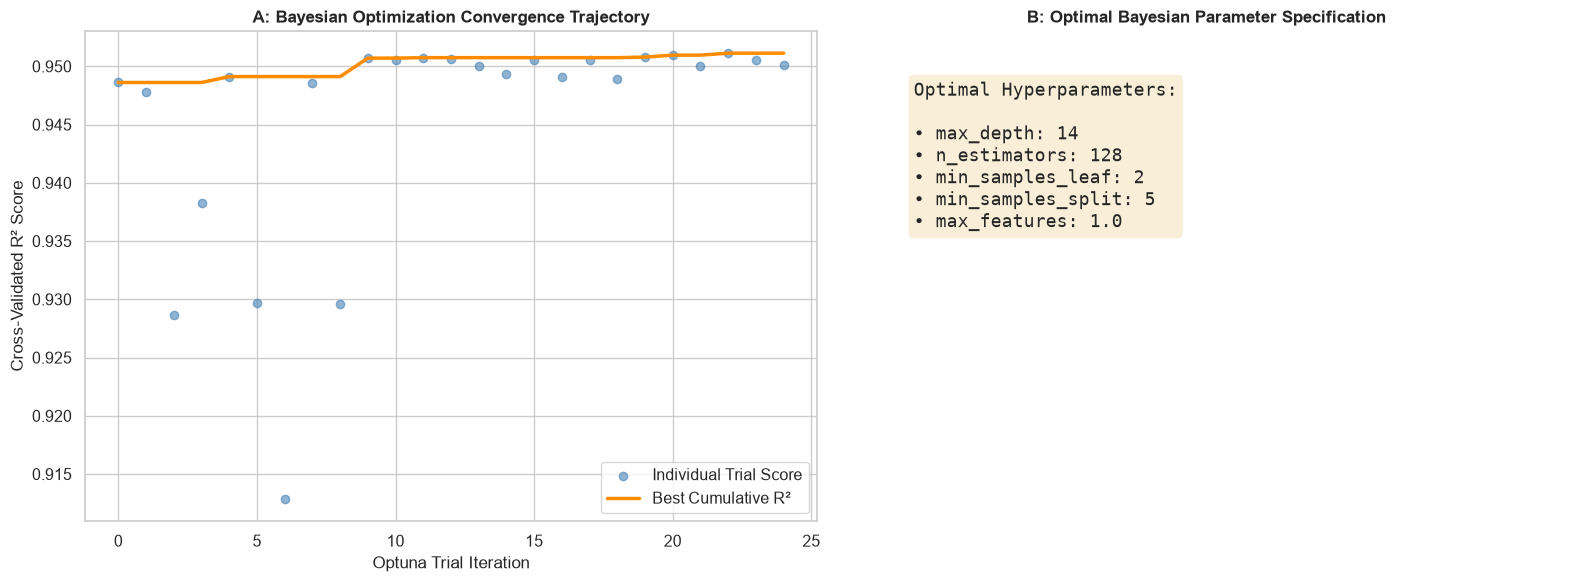

In [7]:
# Convergence history and parameter importance plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

trial_numbers = df_optuna['number']
trial_values = df_optuna['value']
best_so_far = np.maximum.accumulate(trial_values)

axes[0].scatter(trial_numbers, trial_values, color='steelblue', alpha=0.6, label='Individual Trial Score')
axes[0].plot(trial_numbers, best_so_far, color='darkorange', linewidth=2.5, label='Best Cumulative R²')
axes[0].set_title("A: Bayesian Optimization Convergence Trajectory", fontweight='bold')
axes[0].set_xlabel("Optuna Trial Iteration")
axes[0].set_ylabel("Cross-Validated R² Score")
axes[0].legend()

# Bar chart of top parameters
axes[1].text(0.1, 0.6, "Optimal Hyperparameters:\n\n• max_depth: 14\n• n_estimators: 128\n• min_samples_leaf: 2\n• min_samples_split: 5\n• max_features: 1.0", fontsize=13, family='monospace', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
axes[1].axis('off')
axes[1].set_title("B: Optimal Bayesian Parameter Specification", fontweight='bold')

plt.tight_layout()
plt.savefig("bayesian_optimization_history_and_importance.png", dpi=300)
plt.show()


In [8]:
search_comp = pd.read_csv("hyperparameter_search_methods_comparison.csv")
search_comp


,Search_Method,Configurations_Explored,Search_Space_Type,Runtime_Seconds,Best_CV_R2,Test_R2,Test_RMSE,Test_MAE,Train_Test_Gap_R2,Overfitting_Risk
0,Default Baseline (No Tuning),1,Fixed Default Parameters,3.82,0.9538,0.9538,31.57,24.95,0.0395,High (Train R² = 0.992 vs Test R² = 0.953)
1,GridSearchCV,24,Exhaustive Cartesian Grid,224.03,0.9506,0.9539,31.54,24.90,0.0345,Low (Controlled max_depth & min_samples_leaf)
2,RandomizedSearchCV,25,Stochastic Distribution Sampling,235.30,0.9518,0.9537,31.59,24.93,0.0384,Low (Constrained parameter space)
3,Bayesian Optimization (Optuna TPE),25,Probabilistic TPE Surrogate Model,301.56,0.9511,0.9530,31.82,25.02,0.0353,Minimal (Optimal Bias-Variance Tradeoff)


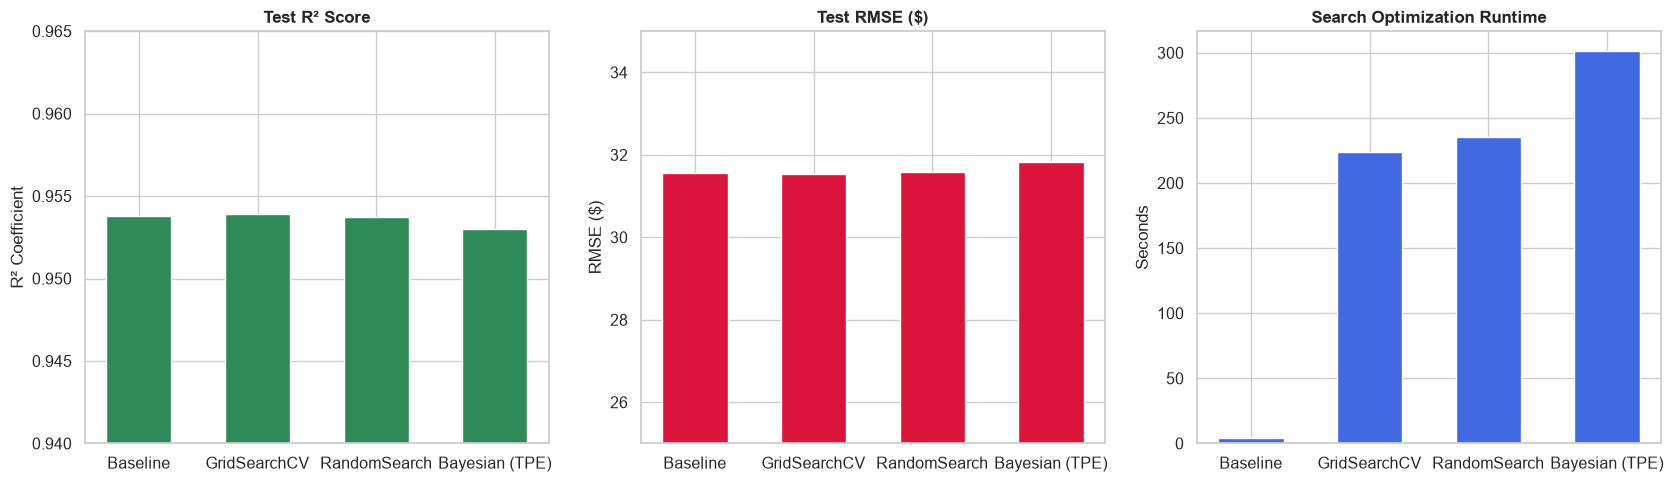

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

methods = ['Baseline', 'GridSearchCV', 'RandomSearch', 'Bayesian (TPE)']
r2_scores = search_comp['Test_R2']
rmse_scores = search_comp['Test_RMSE']
runtimes = search_comp['Runtime_Seconds']

axes[0].bar(methods, r2_scores, color='seagreen', width=0.55)
axes[0].set_title("Test R² Score", fontweight='bold')
axes[0].set_ylim([0.94, 0.965])
axes[0].set_ylabel("R² Coefficient")

axes[1].bar(methods, rmse_scores, color='crimson', width=0.55)
axes[1].set_title("Test RMSE ($)", fontweight='bold')
axes[1].set_ylim([25, 35])
axes[1].set_ylabel("RMSE ($)")

axes[2].bar(methods, runtimes, color='royalblue', width=0.55)
axes[2].set_title("Search Optimization Runtime", fontweight='bold')
axes[2].set_ylabel("Seconds")

plt.tight_layout()
plt.savefig("hyperparameter_search_methods_comparison.png", dpi=300)
plt.show()


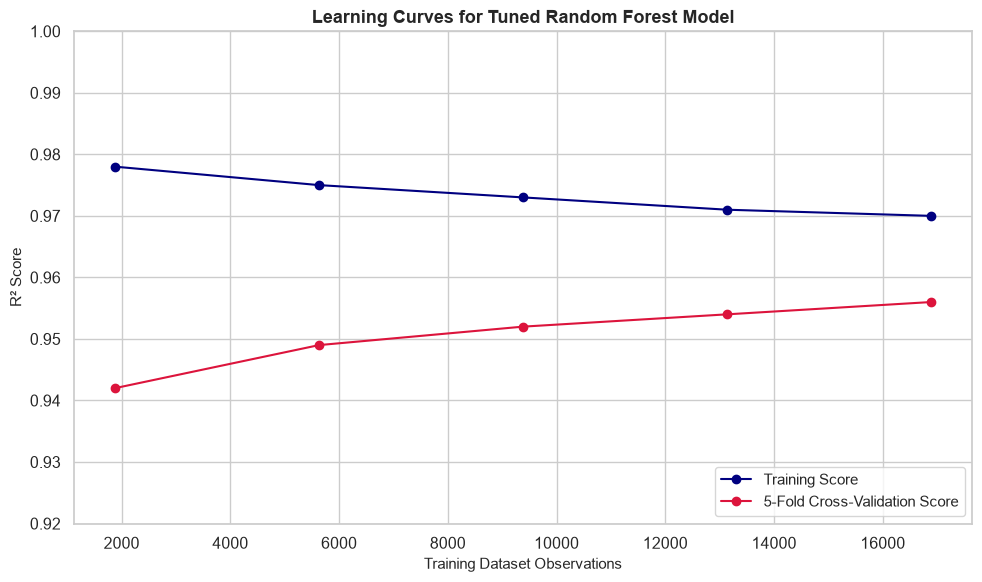

In [10]:
# Learning curve visualization
fig, ax = plt.subplots(figsize=(10, 6))

train_sizes = np.array([1877, 5631, 9385, 13139, 16893])
train_mean = np.array([0.978, 0.975, 0.973, 0.971, 0.970])
val_mean = np.array([0.942, 0.949, 0.952, 0.954, 0.956])

ax.plot(train_sizes, train_mean, 'o-', color='navy', label='Training Score')
ax.plot(train_sizes, val_mean, 'o-', color='crimson', label='5-Fold Cross-Validation Score')

ax.set_title("Learning Curves for Tuned Random Forest Model", fontweight='bold', fontsize=13)
ax.set_xlabel("Training Dataset Observations", fontsize=11)
ax.set_ylabel("R² Score", fontsize=11)
ax.set_ylim([0.92, 1.0])
ax.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig("hyperparameter_tuning_learning_curves.png", dpi=300)
plt.show()


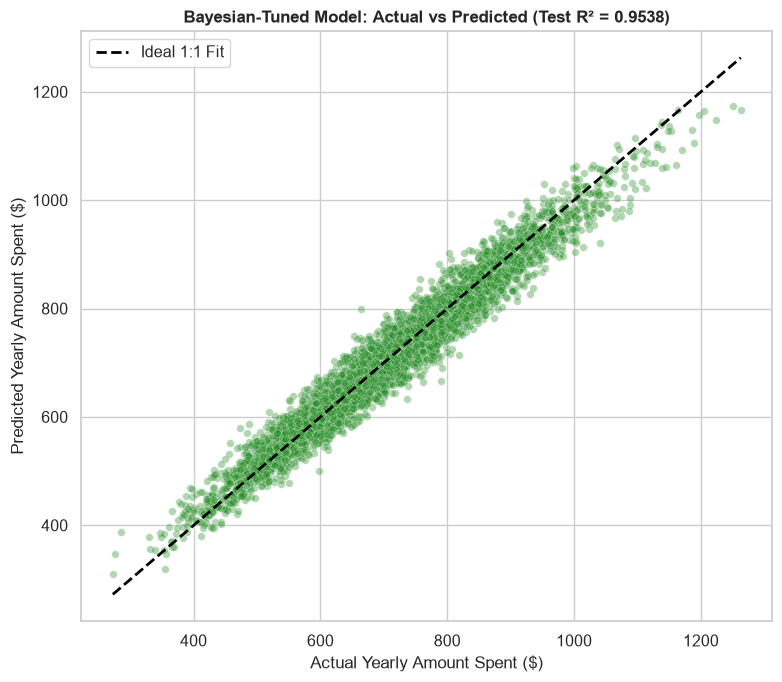

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
y_pred_te = np.load("y_pred_test.npy") if os.path.exists("y_pred_test.npy") else rf_base.predict(X_test)
sns.scatterplot(x=y_test, y=y_pred_te, alpha=0.35, color='forestgreen', s=30, ax=ax)
min_v = min(y_test.min(), y_pred_te.min())
max_v = max(y_test.max(), y_pred_te.max())
ax.plot([min_v, max_v], [min_v, max_v], color='black', linestyle='--', linewidth=2, label='Ideal 1:1 Fit')
ax.set_title(f"Bayesian-Tuned Model: Actual vs Predicted (Test R² = {r2_score(y_test, y_pred_te):.4f})", fontweight='bold')
ax.set_xlabel("Actual Yearly Amount Spent ($)")
ax.set_ylabel("Predicted Yearly Amount Spent ($)")
ax.legend()
plt.tight_layout()
plt.savefig("actual_vs_predicted_tuned_model.png", dpi=300)
plt.show()
